# Week 04 - k-최근접 이웃 회귀

## 4-1. 회귀 알고리즘

농어의 길이를 이용하여 무게를 예측하고,
k-최근접 이웃 회귀 모델의 성능을 평가한다.

훈련 데이터와 테스트 데이터의 성능을 비교하여
과대적합과 과소적합을 확인한다.

In [12]:
import numpy as np

# 농어 길이 데이터
perch_length = np.array([
    8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6,
    20.0, 21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0,
    22.0, 22.5, 22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6,
    25.0, 25.6, 26.5, 27.3, 27.5, 27.5, 27.5, 28.0, 28.7,
    30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0, 39.0,
    39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0,
    43.5, 44.0
])

# 농어 무게 데이터
perch_weight = np.array([
    5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0,
    85.0, 110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0,
    135.0, 110.0, 130.0, 150.0, 145.0, 150.0, 170.0, 225.0,
    145.0, 188.0, 180.0, 197.0, 218.0, 300.0, 260.0, 265.0,
    250.0, 250.0, 300.0, 320.0, 514.0, 556.0, 840.0, 685.0,
    700.0, 700.0, 690.0, 900.0, 650.0, 820.0, 850.0, 900.0,
    1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0, 1000.0
])

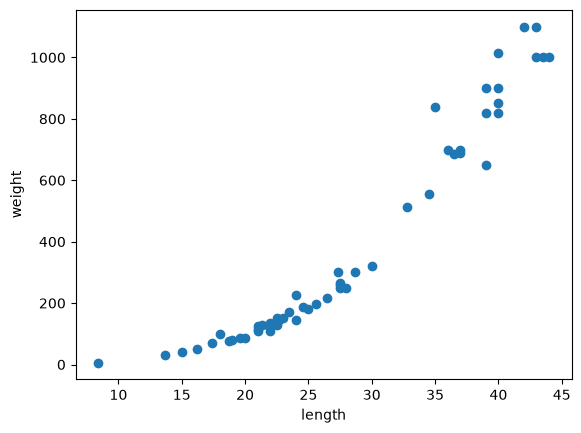

In [13]:
import matplotlib.pyplot as plt

plt.scatter(perch_length, perch_weight)

plt.xlabel('length')
plt.ylabel('weight')

plt.show()

In [14]:
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target = train_test_split(
    perch_length,
    perch_weight,
    random_state=42
)

print(train_input.shape, test_input.shape)

(42,) (14,)


In [15]:
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)
#1차운 배열을 2차원 배열로 바꿔줌
#1은 열은 1개, -1은 Numpy가 전체 데이터 개수에 맞춰 자동으로 계산하라는 의미
# train_input.reshape(42, 1) 같은 결과지만 이게 더 편함

print(train_input.shape, test_input.shape)

(42, 1) (14, 1)


In [16]:
from sklearn.neighbors import KNeighborsRegressor

knr = KNeighborsRegressor()

knr.fit(train_input, train_target)
# train_input → 농어 길이, train_target → 농어 무게

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [17]:
knr.score(test_input, test_target)
#모델 성능 확인

0.992809406101064

In [18]:
#평균적으로 몇 그램이나 예측에서 틀렸는지 알려줌

from sklearn.metrics import mean_absolute_error

test_prediction = knr.predict(test_input)

mae = mean_absolute_error(
    test_target,
    test_prediction
)

print(mae)

19.157142857142862


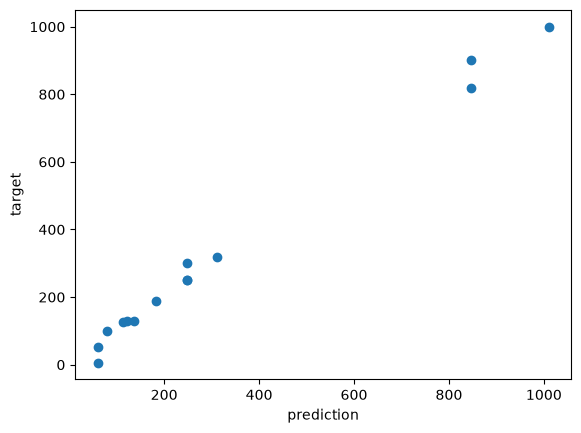

In [19]:
plt.scatter(test_prediction, test_target)

plt.xlabel('prediction') #모델이 예측한 무게
plt.ylabel('target')    #실제 무게

plt.show()

In [20]:
print(knr.score(train_input, train_target)) # 훈련 데이터 점수 확인
print(knr.score(test_input, test_target))   # 테스트 데이터 점수 확인

0.9698823289099254
0.992809406101064


In [22]:
knr.n_neighbors = 3
knr.fit(train_input, train_target)

print(knr.score(train_input, train_target))
print(knr.score(test_input, test_target))

0.9804899950518966
0.9746459963987609


- 과대적합
훈련 데이터 점수 >> 테스트 데이터 점수
훈련 데이터에 너무 맞춰져 있어서 새로운 데이터에는 성능이 떨어지는 상태

- 과소적합
훈련 데이터 점수 < 테스트 데이터 점수 or 둘다 너무 낮은 경우
모델이 너무 단순해서 훈련 데이터의 특징도 충분히 학습하지 못한 상태

- 과소적합을 해결 할 수 있는 방법


- 이웃이 많으면
주변 데이터를 많이 평균냄
→ 결과가 부드러워짐
→ 모델이 단순해짐
→ 과소적합 가능성 ↑

- 이웃이 적으면
가까운 몇 개만 봄
→ 주변 데이터에 민감함
→ 모델이 복잡해짐
→ 과대적합 가능성 ↑

In [21]:
for n in [1, 3, 42]:
    knr.n_neighbors = n

    knr.fit(train_input, train_target)

    print(
        n,
        knr.score(train_input, train_target),
        knr.score(test_input, test_target)
    )

1 0.9852830341215901 0.991309195814175
3 0.9804899950518966 0.9746459963987609
42 0.0 -0.05511282928252759


## 4-1 실습 정리

- 회귀는 클래스가 아닌 연속적인 수치를 예측하는 문제이다.
- k-최근접 이웃 회귀는 가장 가까운 k개 이웃의 타깃 평균을 이용하여 값을 예측한다.
- 농어의 길이를 입력값으로 사용하여 무게를 예측하였다.
- `reshape(-1, 1)`을 이용하여 1차원 입력 데이터를 2차원 배열로 변환하였다.
- `KNeighborsRegressor`를 이용하여 k-최근접 이웃 회귀 모델을 만들었다.
- 회귀 모델에서는 결정계수 R²를 이용하여 모델 성능을 평가할 수 있다.
- `mean_absolute_error()`를 이용하여 실제값과 예측값의 평균 절대 오차를 확인하였다.
- 훈련 데이터와 테스트 데이터의 점수를 비교하여 과대적합과 과소적합을 확인할 수 있다.
- 이웃의 개수를 줄이면 모델이 복잡해지고, 이웃의 개수를 늘리면 모델이 단순해진다.
- 기본 이웃 수 5에서 3으로 줄여 과소적합을 개선하였다.